# Практика 5. Надёжный конвейер акустической диагностики

Модель должна предсказуемо работать не только на корректном примере. В этой работе
мы проверим модельный комплект и входные данные, обработаем типовые сбои, проведём
пакетную диагностику и сформируем журнал, пригодный для разбора результатов.

Шкала 0–100 отражает выход учебной модели. Она не является измеренным физическим
процентом износа и требует калибровки перед использованием в реальной системе.

## 1. Подготовка

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.io import loadmat, wavfile
from scipy.signal import hilbert
from scipy.stats import skew, kurtosis

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True})

DATA = Path("data_seminar")
MODEL_PATH = DATA / "bearing_models_python.joblib"

## 2. Контракт модельного комплекта

Сохранять нужно не только модели, но и параметры предобработки. Проверка контракта
помогает обнаружить неполный или несовместимый файл до начала расчётов.

In [4]:
FEATURE_NAMES = [
    "mean", "median", "rms", "std", "variance", "maximum", "minimum", "range",
    "skewness", "kurtosis", "crest_ratio", "impulse_ratio", "shape_ratio", "time_energy",
    "spectral_max", "dominant_frequency", "spectral_centroid", "spectral_width",
    "spectral_entropy", "spectral_flatness", "mean_frequency", "median_frequency",
    "rolloff_85", "spectral_energy", "spectral_std", "spectral_skewness",
    "spectral_kurtosis",
    *[f"band_{low}_{low + 500}" for low in range(0, 5000, 500)],
    "envelope_spectral_max", "envelope_frequency", "envelope_spectral_energy",
    "envelope_entropy", "envelope_centroid", "envelope_mean", "envelope_std",
    "envelope_max", "envelope_kurtosis", "zero_crossing_rate", "high_mid_low_ratio",
    "envelope_energy_ratio", "absolute_crest_ratio", "fraction_below_q25",
    "small_to_large_amplitude", "small_to_large_energy", "q75_to_q25",
]


def extract_features(signal, fs=10_000):
    """54 time, spectrum and envelope features; one row per 0.4 s window."""
    x = np.asarray(signal, dtype=float)
    centered = x - x.mean()
    absolute = np.abs(centered)
    rms = np.sqrt(np.mean(centered ** 2))
    abs_mean = absolute.mean()
    eps = 1e-10

    time_features = [
        x.mean(), np.median(x), rms, centered.std(ddof=1),
        centered.var(ddof=1), x.max(), x.min(), np.ptp(x),
        skew(centered), kurtosis(centered), x.max() / (rms + eps),
        x.max() / (abs_mean + eps), rms / (abs_mean + eps),
        np.sum(centered ** 2),
    ]

    amplitude = np.abs(np.fft.rfft(centered))[:-1]  # exclude the Nyquist bin as in source
    frequency = np.fft.rfftfreq(len(x), d=1 / fs)[:-1]
    weights = amplitude / (amplitude.sum() + eps)
    cumulative = np.cumsum(weights)
    centroid = np.sum(frequency * weights)
    positive = weights[weights > 0]
    flatness = np.exp(np.mean(np.log(positive))) / (weights.mean() + eps)
    spectral_features = [
        amplitude.max(), frequency[np.argmax(amplitude)], centroid,
        np.sqrt(np.sum((frequency - centroid) ** 2 * weights)),
        -np.sum(positive * np.log(positive)), flatness, centroid,
        frequency[min(np.searchsorted(cumulative, 0.5), len(frequency) - 1)],
        frequency[min(np.searchsorted(cumulative, 0.85), len(frequency) - 1)],
        np.sum(amplitude ** 2), amplitude.std(ddof=1),
        skew(amplitude), kurtosis(amplitude),
    ]

    band_energy = np.array([
        np.sum(amplitude[(frequency >= low) & (frequency < low + 500)] ** 2)
        for low in range(0, 5000, 500)
    ])

    envelope = np.abs(hilbert(centered))
    env_amplitude = np.abs(np.fft.rfft(envelope - envelope.mean()))[:-1]
    env_weights = env_amplitude / (env_amplitude.sum() + eps)
    env_positive = env_weights[env_weights > 0]
    envelope_features = [
        env_amplitude.max(), frequency[np.argmax(env_amplitude)],
        np.sum(env_amplitude ** 2),
        -np.sum(env_positive * np.log(env_positive)),
        np.sum(frequency * env_weights),
    ]

    q25, _, q75 = np.quantile(absolute, [0.25, 0.5, 0.75])
    small = absolute[absolute < q25]
    large = absolute[absolute > q75]
    high_energy = band_energy[7:].sum()
    mid_energy = band_energy[3:7].sum()
    low_energy = band_energy[:3].sum()
    extra = [
        envelope.mean(), envelope.std(ddof=1), envelope.max(), kurtosis(envelope),
        np.count_nonzero(np.diff(np.sign(centered))) / len(x),
        (high_energy + mid_energy) / (low_energy + eps),
        np.sum(env_amplitude ** 2) / (np.sum(amplitude ** 2) + eps),
        absolute.max() / (rms + eps),
        len(small) / len(x),
        small.mean() / (large.mean() + eps),
        np.sum(small ** 2) / (np.sum(large ** 2) + eps),
        q75 / (q25 + eps),
    ]
    result = np.asarray(time_features + spectral_features + band_energy.tolist()
                        + envelope_features + extra, dtype=float)
    assert len(result) == len(FEATURE_NAMES) == 54
    return result

In [5]:
REQUIRED_BUNDLE_KEYS = {
    "models", "scaler", "feature_names", "fs",
    "segment_length", "overlap", "label_order",
}
REQUIRED_SIGNAL_KEYS = {"normal", "inner", "outer", "roller"}


def validate_bundle(bundle):
    """Проверить состав и согласованность модельного комплекта."""
    missing = REQUIRED_BUNDLE_KEYS - set(bundle)
    if missing:
        raise ValueError(f"В модельном комплекте нет ключей: {sorted(missing)}")
    labels = list(bundle["label_order"])
    if set(bundle["models"]) != set(labels):
        raise ValueError("Набор моделей не совпадает с label_order")
    if len(bundle["feature_names"]) != len(bundle["scaler"].mean_):
        raise ValueError("Число признаков не совпадает с параметрами scaler")
    if bundle["fs"] <= 0 or bundle["segment_length"] <= 0:
        raise ValueError("Частота и длина окна должны быть положительными")
    if not 0 <= bundle["overlap"] < 1:
        raise ValueError("Перекрытие должно находиться в диапазоне [0, 1)")
    return True


def validate_mat(path):
    """Проверить, что MAT-файл содержит четыре непустых одномерных сигнала."""
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(path)
    raw = loadmat(path)
    missing = REQUIRED_SIGNAL_KEYS - set(raw)
    if missing:
        raise ValueError(f"В MAT-файле нет сигналов: {sorted(missing)}")
    signals = {key: np.asarray(raw[key], dtype=float).squeeze()
               for key in sorted(REQUIRED_SIGNAL_KEYS)}
    bad = [key for key, value in signals.items()
           if value.ndim != 1 or value.size == 0 or not np.isfinite(value).all()]
    if bad:
        raise ValueError(f"Некорректные сигналы: {bad}")
    return signals


def read_wav_checked(path, expected_fs):
    """Прочитать WAV и проверить формат, частоту и длину."""
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(path)
    rate, signal = wavfile.read(path)
    original_dtype = signal.dtype
    signal = np.asarray(signal, dtype=float)
    if signal.ndim == 2:
        signal = signal.mean(axis=1)
    if signal.ndim != 1 or signal.size == 0:
        raise ValueError("Ожидается непустой моно- или стереосигнал")
    if rate != expected_fs:
        raise ValueError(f"Ожидалось {expected_fs} Гц, получено {rate} Гц")
    if np.issubdtype(original_dtype, np.integer):
        signal = signal / max(abs(np.iinfo(original_dtype).min), np.iinfo(original_dtype).max)
    if not np.isfinite(signal).all():
        raise ValueError("Сигнал содержит NaN или бесконечные значения")
    return rate, signal


def segment_signal(signal, length, overlap):
    signal = np.asarray(signal, dtype=float).squeeze()
    step = int(length * (1 - overlap))
    if signal.ndim != 1 or step < 1 or len(signal) < length:
        raise ValueError("Сигнал слишком короткий или неверно заданы окна")
    return np.stack([signal[start:start + length]
                     for start in range(0, len(signal) - length + 1, step)])


def diagnose_signal(signal, bundle):
    windows = segment_signal(signal, bundle["segment_length"], bundle["overlap"])
    features = np.vstack([extract_features(window, bundle["fs"]) for window in windows])
    scaled = bundle["scaler"].transform(features)
    frame = pd.DataFrame({label: bundle["models"][label].predict(scaled)
                          for label in bundle["label_order"]})
    summary = frame.agg(["mean", "std", "max"]).T
    summary["mean"] = summary["mean"].clip(0, 100)
    return summary.round(1), frame


def state_label(value):
    if value <= 10:
        return "идеальное состояние"
    if value <= 20:
        return "хорошее состояние"
    if value <= 50:
        return "средний износ"
    if value <= 75:
        return "сильный износ"
    return "критический износ"


def inspect_wav(path, bundle):
    """Вернуть структурированный результат, не прерывая пакетную обработку."""
    path = Path(path)
    result = {"file": path.name, "status": "error", "message": ""}
    try:
        rate, signal = read_wav_checked(path, bundle["fs"])
        summary, windows = diagnose_signal(signal, bundle)
        result.update({
            "status": "ok", "message": "обработан", "sample_rate": rate,
            "samples": len(signal), "windows": len(windows),
        })
        for label in bundle["label_order"]:
            result[label] = float(summary.loc[label, "mean"])
    except FileNotFoundError:
        result["message"] = "файл не найден"
    except ValueError as exc:
        result["message"] = str(exc)
    except Exception as exc:
        result["message"] = f"не удалось прочитать: {type(exc).__name__}"
    return result

In [6]:
bundle = joblib.load(MODEL_PATH)
validate_bundle(bundle)
pd.Series({
    "моделей": len(bundle["models"]),
    "признаков": len(bundle["feature_names"]),
    "частота, Гц": bundle["fs"],
    "длина окна": bundle["segment_length"],
    "перекрытие": bundle["overlap"],
}).to_frame("значение")

C:\Users\Ярослав\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeRegressor from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\Ярослав\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestRegressor from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\Ярослав\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying

,значение
моделей,3.00
признаков,54.00
"частота, Гц",10000.00
длина окна,4000.00
перекрытие,0.75


## 3. Проверка MAT-файла

Имя файла недостаточно: проверяем обязательные ключи, размерность, длину и конечность значений.

In [7]:
signals = validate_mat(DATA / "Bearing.mat")
pd.DataFrame({
    "сигнал": signals.keys(),
    "отсчётов": [len(x) for x in signals.values()],
    "RMS": [np.sqrt(np.mean((x - x.mean()) ** 2)) for x in signals.values()],
})

,сигнал,отсчётов,RMS
0,inner,120000,0.291079
1,normal,120000,0.072674
2,outer,120000,0.668851
3,roller,120000,0.138533


In [8]:
try:
    validate_mat(DATA / "Bearing_0.mat")
except ValueError as exc:
    print("Ожидаемая ошибка структуры:", exc)

Ожидаемая ошибка структуры: В MAT-файле нет сигналов: ['inner', 'normal', 'outer', 'roller']


## 4. Контролируемые ошибки WAV

Проверим четыре ситуации отдельно: отсутствующий файл, неверный формат, другая
частота дискретизации и корректная запись. Пакетная система должна сообщать причину,
а не завершаться на первом проблемном файле.

In [9]:
test_paths = [
    DATA / "Подшипник_0.wav",
    DATA / "Подшипник_.wav",
    DATA / "Подшипник_чд.wav",
    DATA / "Подшипник_1.wav",
]
pd.DataFrame(inspect_wav(path, bundle) for path in test_paths).fillna("—")

,file,status,message,sample_rate,samples,windows,inner,outer,roller
0,Подшипник_0.wav,error,файл не найден,—,—,—,—,—,—
1,Подшипник_.wav,error,File format b'\x89PNG' not understood. Only 'R...,—,—,—,—,—,—
2,Подшипник_чд.wav,error,"Ожидалось 10000 Гц, получено 42000 Гц",—,—,—,—,—,—
3,Подшипник_1.wav,ok,обработан,10000.0,120000.0,117.0,0.2,0.1,0.4


## 5. Пакетная диагностика

Обработаем 15 записей. Сортировка выполняется по числу в имени файла, чтобы порядок
не зависел от файловой системы.

In [10]:
wav_paths = sorted(
    [p for p in DATA.glob("Подшипник_[0-9]*.wav")],
    key=lambda p: int(p.stem.rsplit("_", 1)[1]),
)
audit = pd.DataFrame(inspect_wav(path, bundle) for path in wav_paths)
assert len(audit) == 15 and (audit["status"] == "ok").all()
display(audit.head())
print("Обработано записей:", len(audit))

,file,status,message,sample_rate,samples,windows,inner,outer,roller
0,Подшипник_1.wav,ok,обработан,10000,120000,117,0.2,0.1,0.4
1,Подшипник_2.wav,ok,обработан,10000,120000,117,0.2,0.1,8.4
2,Подшипник_3.wav,ok,обработан,10000,120000,117,0.9,0.9,76.4
3,Подшипник_4.wav,ok,обработан,10000,120000,117,86.8,1.5,6.9
4,Подшипник_5.wav,ok,обработан,10000,120000,117,21.6,53.6,45.7


Обработано записей: 15


## 6. Карта оценок и инженерные категории

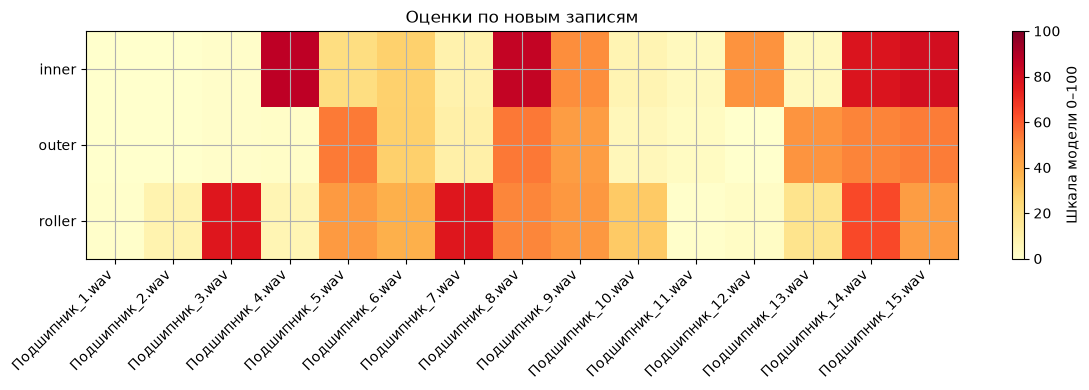

,inner,outer,roller
file,,,
Подшипник_1.wav,идеальное состояние,идеальное состояние,идеальное состояние
Подшипник_2.wav,идеальное состояние,идеальное состояние,идеальное состояние
Подшипник_3.wav,идеальное состояние,идеальное состояние,критический износ
Подшипник_4.wav,критический износ,идеальное состояние,идеальное состояние
Подшипник_5.wav,средний износ,сильный износ,средний износ


In [11]:
labels = bundle["label_order"]
scores = audit.set_index("file")[labels]
fig, ax = plt.subplots(figsize=(12, 4))
image = ax.imshow(scores.T, cmap="YlOrRd", vmin=0, vmax=100, aspect="auto")
ax.set(xticks=range(len(scores)), xticklabels=scores.index,
       yticks=range(len(labels)), yticklabels=labels,
       title="Оценки по новым записям")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.colorbar(image, ax=ax, label="Шкала модели 0–100")
plt.tight_layout(); plt.show()

categories = scores.map(state_label)
display(categories.head())

## 7. Смотрим не только среднее

Среднее скрывает локальные всплески. Для записи с наибольшей суммой оценок сравним
среднее, стандартное отклонение и максимум по окнам.

Выбрана запись: Подшипник_14.wav


,mean,std,max
inner,77.4,3.8,84.4
outer,51.6,1.3,53.5
roller,63.7,8.7,77.0


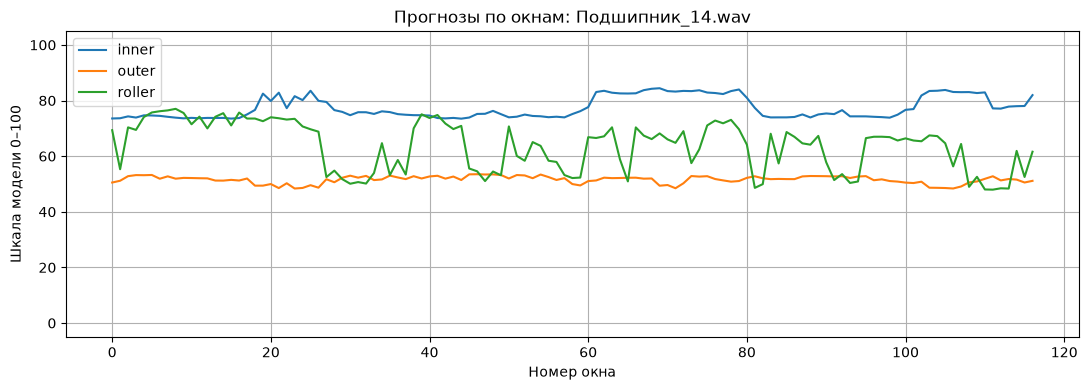

In [12]:
selected_name = scores.sum(axis=1).idxmax()
_, selected_signal = read_wav_checked(DATA / selected_name, bundle["fs"])
selected_summary, selected_windows = diagnose_signal(selected_signal, bundle)
print("Выбрана запись:", selected_name)
display(selected_summary)

ax = selected_windows.plot(figsize=(11, 4), title=f"Прогнозы по окнам: {selected_name}")
ax.set(xlabel="Номер окна", ylabel="Шкала модели 0–100", ylim=(-5, 105))
plt.tight_layout(); plt.show()

## 8. Журнал обработки

Журнал фиксирует входной файл, статус, причину отказа, параметры сигнала и результат.
Такой формат можно сохранить в CSV или передать следующему компоненту системы.

In [13]:
all_paths = test_paths[:3] + wav_paths
full_audit = pd.DataFrame(inspect_wav(path, bundle) for path in all_paths)
full_audit.to_csv("diagnostic_audit.csv", index=False)
display(full_audit[["file", "status", "message", "sample_rate", "samples", "windows"]]
        .fillna("—"))
print("Журнал сохранён: diagnostic_audit.csv")

,file,status,message,sample_rate,samples,windows
0,Подшипник_0.wav,error,файл не найден,—,—,—
1,Подшипник_.wav,error,File format b'\x89PNG' not understood. Only 'R...,—,—,—
2,Подшипник_чд.wav,error,"Ожидалось 10000 Гц, получено 42000 Гц",—,—,—
3,Подшипник_1.wav,ok,обработан,10000.0,120000.0,117.0
4,Подшипник_2.wav,ok,обработан,10000.0,120000.0,117.0
5,Подшипник_3.wav,ok,обработан,10000.0,120000.0,117.0
6,Подшипник_4.wav,ok,обработан,10000.0,120000.0,117.0
7,Подшипник_5.wav,ok,обработан,10000.0,120000.0,117.0
8,Подшипник_6.wav,ok,обработан,10000.0,120000.0,117.0
9,Подшипник_7.wav,ok,обработан,10000.0,120000.0,117.0


Журнал сохранён: diagnostic_audit.csv


## Вывод

Надёжность конвейера обеспечивается явными контрактами, проверкой входных данных,
контролируемой обработкой исключений и журналированием. Прогноз модели становится
полезным только тогда, когда вместе с ним известны качество входа и статус расчёта.